# Assignment 2 — News Classification Model
Pipeline: raw text → preprocessing → TF-IDF features → model building → evaluation → deployment (Streamlit).

## 1. Load data
The CSV has `publish_date`, `headline_category`, `headline_text`. **To use another dataset (e.g. the Akashvani bulletins), only this cell and the label-mapping cell change.**

In [1]:
import re, json, joblib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

CSV = "india-news-headlines.csv"   # change path if needed
df = pd.read_csv(CSV)
print(df.shape)
df.head()

(3876557, 3)


,publish_date,headline_category,headline_text
0,20010102,unknown,Status quo will not be disturbed at Ayodhya; s...
1,20010102,unknown,Fissures in Hurriyat over Pak visit
2,20010102,unknown,America's unwanted heading for India?
3,20010102,unknown,For bigwigs; it is destination Goa
4,20010102,unknown,Extra buses to clear tourist traffic


## 2. Exploratory analysis & label mapping
The raw file has ~1,000 fine-grained categories (e.g. `city.mumbai`, `sports.tennis`). Take the top-level prefix and keep 7 broad topics.

In [2]:
df["top"] = df["headline_category"].str.split(".").str[0]
print("Raw categories:", df["headline_category"].nunique())
print(df["top"].value_counts().head(10))

MAP = {"india":"National","business":"Business","entertainment":"Entertainment",
       "sports":"Sports","world":"World","tech":"Technology","life-style":"Lifestyle"}
df["label"] = df["top"].map(MAP)
df = df.dropna(subset=["label"])[["headline_text","label"]].drop_duplicates()
print("\nAfter mapping:"); print(df["label"].value_counts())

Raw categories: 1024


top
city             2315473
india             307371
entertainment     236436
unknown           209583
business          165698
sports            131926
home              100581
world              69385
life-style         46920
tv                 39936
Name: count, dtype: int64



After mapping:
label
National         305758
Entertainment    229561
Business         160342
Sports           126442
World             67980
Lifestyle         45215
Technology        33944
Name: count, dtype: int64


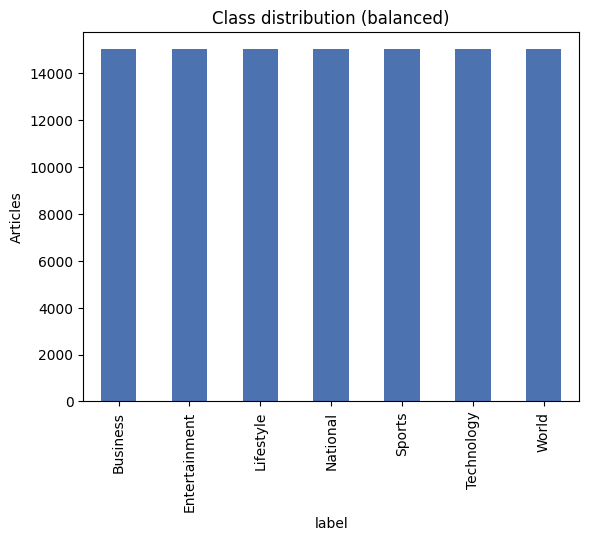

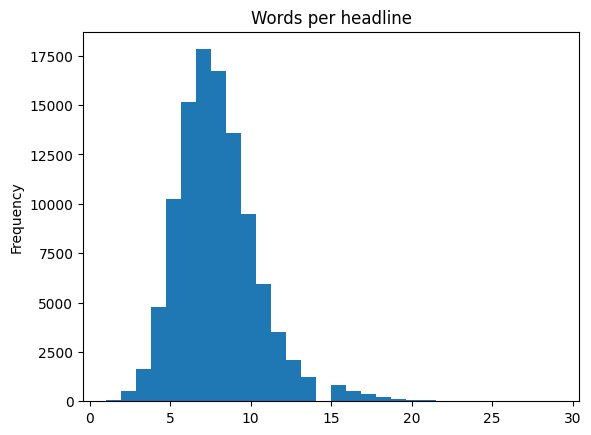

In [3]:
# Balance the classes (15,000 per class) so accuracy is not dominated by big classes
PER_CLASS, SEED = 15000, 42
df = pd.concat([g.sample(min(len(g), PER_CLASS), random_state=SEED) for _, g in df.groupby("label")], ignore_index=True)
df["label"].value_counts().plot(kind="bar", title="Class distribution (balanced)", color="#4C72B0")
plt.ylabel("Articles"); plt.show()
df["headline_text"].str.split().str.len().plot(kind="hist", bins=30, title="Words per headline"); plt.show()

## 3. Text preprocessing
Lowercase → remove URLs → keep letters only → collapse whitespace. Stop-word removal and n-grams are handled inside the TF-IDF step.

In [4]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["headline_text"].astype(str).map(clean)
df = df[df["clean"].str.len() > 2]
df[["headline_text","clean","label"]].sample(5, random_state=1)

,headline_text,clean,label
82295,LG gets aggressive to push India sales,lg gets aggressive to push india sales,Technology
47392,Five Indians missing in Iraq,five indians missing in iraq,National
73195,NBA: Thunder hand Pistons another defeat,nba thunder hand pistons another defeat,Sports
18514,Amitabh Bachchan the biggest crowdpuller at KIFF,amitabh bachchan the biggest crowdpuller at kiff,Entertainment
43542,Raj-era jewellery sparkles globally,raj era jewellery sparkles globally,Lifestyle


## 4. Train / test split (80 / 20, stratified)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)
print(len(X_train), len(X_test))

84000 21000


## 5. Feature representation + model building
TF-IDF (unigrams + bigrams) feeds three classic classifiers. The SVM is wrapped in a calibrator so it outputs real probabilities for the app.

In [6]:
def make(model):
    return Pipeline([("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1,2), min_df=2, sublinear_tf=True)),
                     ("clf", model)])

candidates = {
    "Naive Bayes": make(MultinomialNB(alpha=0.3)),
    "Logistic Regression": make(LogisticRegression(max_iter=1000, C=5)),
    "Linear SVM": make(CalibratedClassifierCV(LinearSVC(C=0.5), cv=3)),
}
results, fitted = {}, {}
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = {"accuracy": accuracy_score(y_test, pred), "macro_f1": f1_score(y_test, pred, average="macro")}
    fitted[name] = pipe
pd.DataFrame(results).T.round(4)

,accuracy,macro_f1
Naive Bayes,0.7902,0.790
Logistic Regression,0.7929,0.793
Linear SVM,0.8022,0.802


## 6. Evaluation of the best model

Best model: Linear SVM
               precision    recall  f1-score   support

     Business      0.783     0.750     0.766      3000
Entertainment      0.802     0.817     0.809      3000
    Lifestyle      0.766     0.796     0.781      3000
     National      0.757     0.720     0.738      3000
       Sports      0.900     0.904     0.902      3000
   Technology      0.830     0.827     0.828      3000
        World      0.778     0.801     0.789      3000

     accuracy                          0.802     21000
    macro avg      0.802     0.802     0.802     21000
 weighted avg      0.802     0.802     0.802     21000



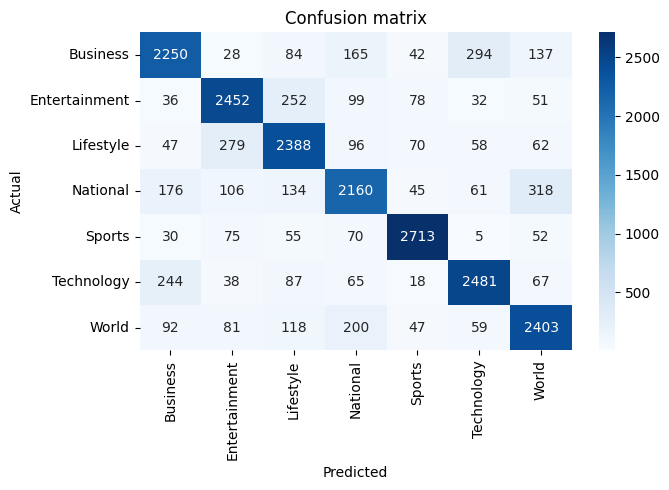

In [7]:
best_name = max(results, key=lambda k: results[k]["macro_f1"])
best = fitted[best_name]; pred = best.predict(X_test)
print("Best model:", best_name)
print(classification_report(y_test, pred, digits=3))
labels = sorted(df["label"].unique())
cm = confusion_matrix(y_test, pred, labels=labels)
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix"); plt.tight_layout(); plt.show()

In [8]:
# Most informative words per class (from a Logistic Regression refit for interpretability)
lr = fitted["Logistic Regression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_
for i, c in enumerate(lr.named_steps["clf"].classes_):
    print(f"{c:14s}", ", ".join(vocab[np.argsort(coef[i])[-8:][::-1]]))

Business       sensex, rbi, gst, inflation, sebi, sbi, stocks, fdi
Entertainment  film, kapoor, song, biopic, films, salman, actress, movie
Lifestyle      recipe, restaurant review, diet, fashion, diabetes, obesity, hair, book
National       bjp, congress, sc, pm, cong, cbi, bihar, govt
Sports         bcci, nba, ipl, football, cup, pcb, icc, dhoni
Technology     google, facebook, infosys, apple, iphone, microsoft, samsung, blackberry
World          pak, china, nepal, pakistan, uk, trump, biden, musharraf


In [9]:
# Error analysis: a few misclassified headlines
err = pd.DataFrame({"text": X_test.values, "actual": y_test.values, "predicted": pred})
err[err.actual != err.predicted].sample(8, random_state=3)

,text,actual,predicted
16946,tamil nadu s arun kumar bags first gold in sho...,Sports,Entertainment
18255,john abraham s fitness fundas,Lifestyle,Entertainment
7599,tovala will replace every cooking appliance yo...,Technology,Lifestyle
1528,watch out your smartphone may be harbouring ba...,Lifestyle,Technology
6843,india r d centres key to mastercard s global o...,Technology,National
19472,tax haven not to be used in indian dossiers,National,Business
4632,indian chinese patrols face off in ladakh again,National,World
5390,deepika padukone looks super hot in this new song,Lifestyle,Entertainment


## 7. Test on new text

In [10]:
for t in ["Sensex jumps 400 points as banking stocks rally",
          "Virat Kohli scores century as India win the test series",
          "Apple launches new iPhone with faster chip",
          "UN Security Council meets over Gaza ceasefire"]:
    p = best.predict_proba([clean(t)])[0]
    print(f"{best.predict([clean(t)])[0]:14s} {p.max():.0%}  <- {t}")

Business       97%  <- Sensex jumps 400 points as banking stocks rally
Sports         97%  <- Virat Kohli scores century as India win the test series
Technology     98%  <- Apple launches new iPhone with faster chip
World          89%  <- UN Security Council meets over Gaza ceasefire


## 8. Save artefacts for deployment
`model.joblib` and `metrics.json` are loaded by `app.py` on Streamlit Cloud.

In [11]:
joblib.dump(best, "model.joblib", compress=3)
json.dump({"best_model": best_name, "results": results, "labels": labels,
           "n_train": len(X_train), "n_test": len(X_test)}, open("metrics.json","w"), indent=2)
print("saved")

saved
